In [3]:
NOI_PATH = "HSNoi.xlsx"
NGOAI_PATH = "hsNgoai.xlsx"

noi = pd.read_excel(NOI_PATH, sheet_name="Export Worksheet")
ngoai = pd.read_excel(NGOAI_PATH, sheet_name="Export Worksheet")


/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


### kiem tra kich thuoc va cot cua du lieu

In [4]:
print("nội:", noi.shape)
print("ngoài:", ngoai.shape)
print("cột:", noi.columns.tolist())

nội: (181, 16)
ngoài: (181, 16)
cột: ['NGAY', 'THU', 'THANG', 'ID_KHOA', 'MA_KHOA', 'TEN_KHOA', 'SO_GIUONG_KE_HOACH', 'BN_DAU_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'BN_CUOI_NGAY', 'SO_GIUONG_DANG_SU_DUNG', 'TRANG_THAI_CAN_DOI', 'CONG_SUAT_GIUONG']


### kiểm tra dữ liệu

In [5]:
print("NULL — NOI")
print(noi.isnull().sum())
print("NULL — NGOAI")
print(ngoai.isnull().sum())

print("\nDup — NOI:", noi.duplicated().sum())
print("Dup — NGOAI:", ngoai.duplicated().sum())

print("\nData types")
print(noi.dtypes)


NULL — NOI
NGAY                      0
THU                       0
THANG                     0
ID_KHOA                   0
MA_KHOA                   0
TEN_KHOA                  0
SO_GIUONG_KE_HOACH        0
BN_DAU_NGAY               0
SO_BN_NHAP_VIEN           0
SO_BN_CHUYEN_DEN          0
SO_BN_RA_VIEN             0
SO_BN_CHUYEN_DI           0
BN_CUOI_NGAY              0
SO_GIUONG_DANG_SU_DUNG    0
TRANG_THAI_CAN_DOI        0
CONG_SUAT_GIUONG          0
dtype: int64
NULL — NGOAI
NGAY                      0
THU                       0
THANG                     0
ID_KHOA                   0
MA_KHOA                   0
TEN_KHOA                  0
SO_GIUONG_KE_HOACH        0
BN_DAU_NGAY               0
SO_BN_NHAP_VIEN           0
SO_BN_CHUYEN_DEN          0
SO_BN_RA_VIEN             0
SO_BN_CHUYEN_DI           0
BN_CUOI_NGAY              0
SO_GIUONG_DANG_SU_DUNG    0
TRANG_THAI_CAN_DOI        0
CONG_SUAT_GIUONG          0
dtype: int64

Dup — NOI: 0
Dup — NGOAI: 0

Data types
NGAY         

### Kiểm tra trạng thái

In [6]:
print(noi["TRANG_THAI_CAN_DOI"].value_counts()) # dropna=False

print("\n",ngoai["TRANG_THAI_CAN_DOI"].value_counts())


TRANG_THAI_CAN_DOI
OK    181
Name: count, dtype: int64

 TRANG_THAI_CAN_DOI
OK    181
Name: count, dtype: int64


### kiểm tra độ khớp dự kiến và thực tế

In [7]:

for name, df in [("NOI", noi), ("NGOAI", ngoai)]:
    du_kien = (
        df["BN_DAU_NGAY"]
        + df["SO_BN_NHAP_VIEN"]
        + df["SO_BN_CHUYEN_DEN"]
        - df["SO_BN_RA_VIEN"]
        - df["SO_BN_CHUYEN_DI"]
    )

    khac_biet = df["BN_CUOI_NGAY"] - du_kien
    bad = df.loc[khac_biet != 0, ["NGAY", "BN_CUOI_NGAY"]].copy()
    bad["khac_biet"] = khac_biet[khac_biet != 0]

    print(f"\n{name}")
    print("Số dòng lệch:", len(bad))
    print(bad)



NOI
Số dòng lệch: 2
         NGAY  BN_CUOI_NGAY  khac_biet
78 2026-03-20            53         -1
79 2026-03-21            55          1

NGOAI
Số dòng lệch: 0
Empty DataFrame
Columns: [NGAY, BN_CUOI_NGAY, khac_biet]
Index: []


## Import thư viện 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import main 

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, AdaBoostRegressor, AdaBoostClassifier
from sklearn.svm import SVR, SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    silhouette_score,
)
from IPython.display import display
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from catboost import CatBoostClassifier

from main import plot_actual_vs_predicted_by_dept

import torch
import torchvision
import torchaudio


ModuleNotFoundError: No module named 'main'

#### đảm bảo kết quả lập lại

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

## ĐỌC HAI FILE EXCEL

In [ ]:
NOI_PATH = "HSNoi.xlsx"
NGOAI_PATH = "hsNgoai.xlsx"

noi = pd.read_excel(NOI_PATH, sheet_name="Export Worksheet")
ngoai = pd.read_excel(NGOAI_PATH, sheet_name="Export Worksheet")


/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


## Kiểm tra

### kiem tra kich thuoc va cot cua du lieu

In [ ]:
print("nội:", noi.shape)
print("ngoài:", ngoai.shape)
print("cột:", noi.columns.tolist())

nội: (181, 16)
ngoài: (181, 16)
cột: ['NGAY', 'THU', 'THANG', 'ID_KHOA', 'MA_KHOA', 'TEN_KHOA', 'SO_GIUONG_KE_HOACH', 'BN_DAU_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'BN_CUOI_NGAY', 'SO_GIUONG_DANG_SU_DUNG', 'TRANG_THAI_CAN_DOI', 'CONG_SUAT_GIUONG']


### kiểm tra dữ liệu

In [ ]:
print("NULL — NOI")
print(noi.isnull().sum())
print("NULL — NGOAI")
print(ngoai.isnull().sum())

print("\nDup — NOI:", noi.duplicated().sum())
print("Dup — NGOAI:", ngoai.duplicated().sum())

print("\nData types")
print(noi.dtypes)


NULL — NOI
NGAY                      0
THU                       0
THANG                     0
ID_KHOA                   0
MA_KHOA                   0
TEN_KHOA                  0
SO_GIUONG_KE_HOACH        0
BN_DAU_NGAY               0
SO_BN_NHAP_VIEN           0
SO_BN_CHUYEN_DEN          0
SO_BN_RA_VIEN             0
SO_BN_CHUYEN_DI           0
BN_CUOI_NGAY              0
SO_GIUONG_DANG_SU_DUNG    0
TRANG_THAI_CAN_DOI        0
CONG_SUAT_GIUONG          0
dtype: int64
NULL — NGOAI
NGAY                      0
THU                       0
THANG                     0
ID_KHOA                   0
MA_KHOA                   0
TEN_KHOA                  0
SO_GIUONG_KE_HOACH        0
BN_DAU_NGAY               0
SO_BN_NHAP_VIEN           0
SO_BN_CHUYEN_DEN          0
SO_BN_RA_VIEN             0
SO_BN_CHUYEN_DI           0
BN_CUOI_NGAY              0
SO_GIUONG_DANG_SU_DUNG    0
TRANG_THAI_CAN_DOI        0
CONG_SUAT_GIUONG          0
dtype: int64

Dup — NOI: 0
Dup — NGOAI: 0

Data types
NGAY         

### Kiểm tra trạng thái

In [ ]:
print(noi["TRANG_THAI_CAN_DOI"].value_counts()) # dropna=False

print("\n",ngoai["TRANG_THAI_CAN_DOI"].value_counts())


TRANG_THAI_CAN_DOI
OK    181
Name: count, dtype: int64

 TRANG_THAI_CAN_DOI
OK    181
Name: count, dtype: int64


### kiểm tra độ khớp dự kiến và thực tế

In [ ]:

for name, df in [("NOI", noi), ("NGOAI", ngoai)]:
    du_kien = (
        df["BN_DAU_NGAY"]
        + df["SO_BN_NHAP_VIEN"]
        + df["SO_BN_CHUYEN_DEN"]
        - df["SO_BN_RA_VIEN"]
        - df["SO_BN_CHUYEN_DI"]
    )

    khac_biet = df["BN_CUOI_NGAY"] - du_kien
    bad = df.loc[khac_biet != 0, ["NGAY", "BN_CUOI_NGAY"]].copy()
    bad["khac_biet"] = khac_biet[khac_biet != 0]

    print(f"\n{name}")
    print("Số dòng lệch:", len(bad))
    print(bad)



NOI
Số dòng lệch: 2
         NGAY  BN_CUOI_NGAY  khac_biet
78 2026-03-20            53         -1
79 2026-03-21            55          1

NGOAI
Số dòng lệch: 0
Empty DataFrame
Columns: [NGAY, BN_CUOI_NGAY, khac_biet]
Index: []


## Chuẩn hoá dữ liệu


### ghép file

In [ ]:
all_data = pd.concat([noi.assign(KHOA="NOI"), ngoai.assign(KHOA="NGOAI")], ignore_index=True)
all_data = all_data.sort_values(["NGAY", "KHOA"]).reset_index(drop=True)

print(all_data.shape)
print(all_data.head())


(362, 17)
        NGAY THU  THANG  ID_KHOA MA_KHOA                            TEN_KHOA  \
0 2026-01-01  T4      1      344    K482  Khoa Hồi Sức Tích Cực - Ngoại Khoa   
1 2026-01-01  T4      1      343    K481               Khoa Hồi Sức Tích Cực   
2 2026-01-02  T5      1      344    K482  Khoa Hồi Sức Tích Cực - Ngoại Khoa   
3 2026-01-02  T5      1      343    K481               Khoa Hồi Sức Tích Cực   
4 2026-01-03  T6      1      344    K482  Khoa Hồi Sức Tích Cực - Ngoại Khoa   

   SO_GIUONG_KE_HOACH  BN_DAU_NGAY  SO_BN_NHAP_VIEN  SO_BN_CHUYEN_DEN  \
0                  45           43                3                 8   
1                  55           54                4                 3   
2                  45           44                6                 4   
3                  55           50                8                 3   
4                  45           44                6                 5   

   SO_BN_RA_VIEN  SO_BN_CHUYEN_DI  BN_CUOI_NGAY  SO_GIUONG_DANG_SU_DUN

### thống kê mô tả
- count : tổng số lượng giá trị
- mean : giá trị trung bình
- std : độ lệch chuẩn 
- min/max
- 25%, 50%, 75%: số lượng nhỏ hơn hoăc bằng số lượng giá trị / nửa còn lại thì lớn hơn nó

In [ ]:


cols = [
    "SO_GIUONG_KE_HOACH",
    "BN_DAU_NGAY",
    "SO_BN_NHAP_VIEN",
    "SO_BN_CHUYEN_DEN",
    "SO_BN_RA_VIEN",
    "SO_BN_CHUYEN_DI",
    "BN_CUOI_NGAY",
    "SO_GIUONG_DANG_SU_DUNG",
    "CONG_SUAT_GIUONG",
]

print(all_data[cols].describe()) #.T

       SO_GIUONG_KE_HOACH  BN_DAU_NGAY  SO_BN_NHAP_VIEN  SO_BN_CHUYEN_DEN  \
count           362.00000   362.000000       362.000000        362.000000   
mean             50.00000    46.709945         5.588398          5.151934   
std               5.00692     4.877032         2.590025          2.852148   
min              45.00000    30.000000         0.000000          0.000000   
25%              45.00000    44.000000         4.000000          3.000000   
50%              50.00000    45.000000         5.000000          5.000000   
75%              55.00000    51.000000         7.000000          7.000000   
max              55.00000    55.000000        16.000000         15.000000   

       SO_BN_RA_VIEN  SO_BN_CHUYEN_DI  BN_CUOI_NGAY  SO_GIUONG_DANG_SU_DUNG  \
count     362.000000       362.000000    362.000000              362.000000   
mean        4.171271         6.618785     46.660221               46.660221   
std         3.352504         3.486179      4.887433                4.

### trích xuất đặc trưng thời gian
- chuẩn hoá chuối thời gian -> giá trị nguyên độc lập
- thứ - ngày - tháng

In [ ]:
all_data = all_data.copy()

all_data["DOW"] = all_data["NGAY"].dt.dayofweek
all_data["MONTH"] = all_data["NGAY"].dt.month
all_data["DAY"] = all_data["NGAY"].dt.day
print(all_data.columns.tolist())

['NGAY', 'THU', 'THANG', 'ID_KHOA', 'MA_KHOA', 'TEN_KHOA', 'SO_GIUONG_KE_HOACH', 'BN_DAU_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'BN_CUOI_NGAY', 'SO_GIUONG_DANG_SU_DUNG', 'TRANG_THAI_CAN_DOI', 'CONG_SUAT_GIUONG', 'KHOA', 'DOW', 'MONTH', 'DAY']


### khai phá đặc trưng Lưu lượng

$$ [
NetFlow_t = Nhập_t + ChuyểnĐến_t - Ra_t - ChuyểnĐi_t
] $$

- (${netflow} > 0$): nhập > xuất => phình to
- (${netflow} < 0$): nhập < xuất => giải toả
- (${netflow} = 0$): nhập = xuất => cân bằng

In [ ]:
all_data["NET_FLOW"] = (
    all_data["SO_BN_NHAP_VIEN"]
    + all_data["SO_BN_CHUYEN_DEN"]
    - all_data["SO_BN_RA_VIEN"]
    - all_data["SO_BN_CHUYEN_DI"]
)
print(all_data.columns.tolist())

['NGAY', 'THU', 'THANG', 'ID_KHOA', 'MA_KHOA', 'TEN_KHOA', 'SO_GIUONG_KE_HOACH', 'BN_DAU_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'BN_CUOI_NGAY', 'SO_GIUONG_DANG_SU_DUNG', 'TRANG_THAI_CAN_DOI', 'CONG_SUAT_GIUONG', 'KHOA', 'DOW', 'MONTH', 'DAY', 'NET_FLOW']


**Lag**

- `lag1`: giá trị ngày trước.
- `lag7`: giá trị 7 ngày trước.


In [ ]:
all_data["LAG_1"] = all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"].shift(1)
all_data["LAG_7"] = all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"].shift(7)
print(all_data.columns.tolist())

['NGAY', 'THU', 'THANG', 'ID_KHOA', 'MA_KHOA', 'TEN_KHOA', 'SO_GIUONG_KE_HOACH', 'BN_DAU_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'BN_CUOI_NGAY', 'SO_GIUONG_DANG_SU_DUNG', 'TRANG_THAI_CAN_DOI', 'CONG_SUAT_GIUONG', 'KHOA', 'DOW', 'MONTH', 'DAY', 'NET_FLOW', 'LAG_1', 'LAG_7']


**Rolling**

- `rolling3`: trung bình 3 ngày gần nhất.
- `rolling7`: trung bình 7 ngày gần nhất.
- `std7`: độ biến động 7 ngày.

> nan: Not a Number

In [ ]:

all_data["ROLL_MEAN_3"] = (
    all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"]
    .transform(lambda s: s.shift(1).rolling(3).mean())
)

all_data["ROLL_MEAN_7"] = (
    all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

all_data["ROLL_STD_7"] = (
    all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"]
    .transform(lambda s: s.shift(1).rolling(7).std())
)

print("cột:", all_data["ROLL_STD_7"].tolist())
print(all_data.columns.tolist())

cột: [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, 0.5345224838248483, 3.2659863237109037, 0.7867957924694419, 3.598941643369749, 0.7867957924694433, 3.4364987719368973, 0.9511897312113443, 3.132015933791495, 1.676163419695048, 2.943920288775949, 2.22539456105674, 2.943920288775949, 2.2990681342044335, 2.984084768360628, 2.2990681342044335, 2.3401261667248785, 2.2886885410853113, 2.4494897427831774, 2.2886885410853113, 2.4494897427831774, 2.070196678027055, 1.112697280528372, 1.825741858350547, 1.1547005383792495, 0.4879500364742539, 2.886751345948128, 0.4879500364742539, 4.111540089159037, 0.4879500364742539, 3.9940431835899006, 0.786795792469435, 3.8668308667927214, 0.786795792469435, 3.988077469754305, 0.786795792469435, 3.988077469754305, 0.786795792469435, 3.988077469754305, 0.786795792469435, 3.4086724129853843, 1.5275252316519423, 1.0690449676496738, 1.4960264830861874, 1.511857892036895, 3.644957377763735, 1.511857892036895, 3.728908942943217, 1.9518001

### tạo var target ngày t+1

In [ ]:

all_data["TARGET_NEXT_BED"] = (
    all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"].shift(-1)
)
all_data["TARGET_1_DAY"] = all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"].shift(-1)

all_data["TARGET_3_DAYS"] = all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"].shift(-3)

all_data["TARGET_7_DAYS"] = all_data.groupby("KHOA")["SO_GIUONG_DANG_SU_DUNG"].shift(-7)


model_data = all_data.dropna().reset_index(drop=True)

print(model_data.columns.tolist())

['NGAY', 'THU', 'THANG', 'ID_KHOA', 'MA_KHOA', 'TEN_KHOA', 'SO_GIUONG_KE_HOACH', 'BN_DAU_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'BN_CUOI_NGAY', 'SO_GIUONG_DANG_SU_DUNG', 'TRANG_THAI_CAN_DOI', 'CONG_SUAT_GIUONG', 'KHOA', 'DOW', 'MONTH', 'DAY', 'NET_FLOW', 'LAG_1', 'LAG_7', 'ROLL_MEAN_3', 'ROLL_MEAN_7', 'ROLL_STD_7', 'TARGET_NEXT_BED', 'TARGET_1_DAY', 'TARGET_3_DAYS', 'TARGET_7_DAYS']


### thiết lập các anh tài tham gia

- liệt kê các cột tham gia phân tích
- làm ma trận x,y,time
- chuẩn hoá dữ liệu cột khoa cho xgboost

In [ ]:
model_data = pd.get_dummies(
    model_data,
    columns=["KHOA"],
    dtype=int,
)

# Giữ lại bản KHOA dạng text (get_dummies đã xoá cột gốc) để dùng cho group/plot/report phía sau
model_data["KHOA"] = np.where(model_data["KHOA_NOI"] == 1, "NOI", "NGOAI")

FEATURE_COLUMNS = [
    "SO_GIUONG_KE_HOACH",
    "DOW",
    "MONTH",
    "BN_CUOI_NGAY",
    "SO_BN_NHAP_VIEN",
    "SO_BN_CHUYEN_DEN",
    "SO_BN_RA_VIEN",
    "SO_BN_CHUYEN_DI",
    "CONG_SUAT_GIUONG",
    "NET_FLOW",
    "LAG_1",
    "LAG_7",
    "ROLL_MEAN_3",
    "ROLL_MEAN_7",
    "ROLL_STD_7",
    "KHOA_NOI",
    "KHOA_NGOAI",
]

X = model_data[FEATURE_COLUMNS].to_numpy(dtype=float)
y = model_data["TARGET_NEXT_BED"].to_numpy(dtype=float)


print("X shape:", X.shape)
print("y shape:", y.shape)



### *chia train / test bằng time series split


In [ ]:

TEST_RATIO = 0.2

# Các ngày duy nhất, đã được sắp xếp
unique_dates = np.sort(model_data["NGAY"].unique())

# Số ngày dành cho Final Test
n_test_dates = int(len(unique_dates) * TEST_RATIO)

# Mốc bắt đầu Final Test
test_start_date = unique_dates[-n_test_dates]

# Mask theo NGÀY, không chia theo row
train_mask = model_data["NGAY"] < test_start_date
test_mask = model_data["NGAY"] >= test_start_date

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

train_dates = model_data.loc[train_mask, "NGAY"]
test_dates = model_data.loc[test_mask, "NGAY"]

print("Train:")
print(train_dates.min(), "→", train_dates.max())
print("Số dòng:", len(X_train))

print("\nFinal Test:")
print(test_dates.min(), "→", test_dates.max())
print("Số dòng:", len(X_test))

train_dates_unique = np.sort(
    model_data.loc[train_mask, "NGAY"].unique()
)

tscv = TimeSeriesSplit(
    n_splits=5
)

folds = []

for train_date_idx, val_date_idx in tscv.split(train_dates_unique):

    train_dates_fold = train_dates_unique[train_date_idx]
    val_dates_fold = train_dates_unique[val_date_idx]

    fold_train_mask = model_data["NGAY"].isin(train_dates_fold)
    fold_val_mask = model_data["NGAY"].isin(val_dates_fold)

    fold_train_idx = np.where(
        train_mask & fold_train_mask
    )[0]

    fold_val_idx = np.where(
        train_mask & fold_val_mask
    )[0]

    folds.append(
        (fold_train_idx, fold_val_idx)
    )

Train:
2026-01-08 00:00:00 → 2026-05-21 00:00:00
Số dòng: 268

Final Test:
2026-05-22 00:00:00 → 2026-06-23 00:00:00
Số dòng: 66


In [ ]:
for i, (train_idx, val_idx) in enumerate(folds, 1):

    train_fold_dates = model_data.loc[train_idx, "NGAY"]
    val_fold_dates = model_data.loc[val_idx, "NGAY"]

    print(
        f"Fold {i}: "
        f"Train {train_fold_dates.min().date()} → {train_fold_dates.max().date()} | "
        f"Valid {val_fold_dates.min().date()} → {val_fold_dates.max().date()}"
    )

Fold 1: Train 2026-01-08 → 2026-01-31 | Valid 2026-02-01 → 2026-02-22
Fold 2: Train 2026-01-08 → 2026-02-22 | Valid 2026-02-23 → 2026-03-16
Fold 3: Train 2026-01-08 → 2026-03-16 | Valid 2026-03-17 → 2026-04-07
Fold 4: Train 2026-01-08 → 2026-04-07 | Valid 2026-04-08 → 2026-04-29
Fold 5: Train 2026-01-08 → 2026-04-29 | Valid 2026-04-30 → 2026-05-21


### danh sách mô hình huấn luyện 

In [ ]:
mo_hinh = {
    # cơ sở
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),

    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB()),
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7, weights="distance")),
    ]),
    
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=1.0, kernel="rbf", class_weight="balanced", probability=True)),
    ]),
    
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, 
        min_samples_leaf=4, 
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400,
        max_depth=8,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    # bootsting
    "AdaBoost": AdaBoostClassifier(
        n_estimators=500,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=RANDOM_STATE
    ),

    # "XGBoost": XGBRegressor(
    #     n_estimators=500,
    #     learning_rate=0.05,
    #     max_depth=6,
    #     subsample=0.8,
    #     random_state=RANDOM_STATE,
    #     n_jobs=-1,
    # ),

    # "LightGBM": LGBMClassifier(
    #     n_estimators=300,
    #     learning_rate=0.05,
    #     max_depth=6,
    #     num_leaves=31,
    #     class_weight="balanced",
    #     random_state=RANDOM_STATE,
    #     n_jobs=-1,
    #     verbose=-1
    # )
}



## thiết lập các giá trị cơ sở

$$[
\hat{y}_{t+1}=y_t
]$$
**số giường ngày mai = số giường hôm nay**



> hàm đo lường và đánh giá hiệu suất của các mô hình hồi quy

 y_true : danh sách chứa các giá trị thực 

 y_pred : mạng dự báo từ mô hình

- MAE : sai số tuyệt đối trung bình
- RMSE : căn hai số toàn cục trung bình
- R2 : hệ số xác định
- MAPE : phân trăm MAE

In [ ]:
def so_lieu_hoi_quy(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))) * 100
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape}

In [ ]:
so_giuong_t = (
    model_data.loc[val_idx, "LAG_1"]
    .to_numpy(dtype=float)
)

y_val = (
    model_data.loc[val_idx, "TARGET_NEXT_BED"]
    .to_numpy(dtype=float)
)

print(so_lieu_hoi_quy(y_val, so_giuong_t))

{'MAE': 2.4545454545454546, 'RMSE': np.float64(3.1766191290283907), 'R2': 0.23168285680575762, 'MAPE': np.float64(5.366607055726956)}


## benchmark

In [ ]:
results = []

for name, model in mo_hinh.items():

    fold_mae = []
    fold_rmse = []
    fold_r2 = []

    for train_idx, val_idx in folds:

        model_fold = clone(model)

        model_fold.fit(
            X[train_idx],
            y[train_idx]
        )

        pred = model_fold.predict(
            X[val_idx]
        )

        fold_mae.append(
            mean_absolute_error(
                y[val_idx],
                pred
            )
        )

        fold_rmse.append(
            np.sqrt(
                mean_squared_error(
                    y[val_idx],
                    pred
                )
            )
        )

        fold_r2.append(
            r2_score(
                y[val_idx],
                pred
            )
        )

    results.append({
        "Model": name,
        "MAE": np.mean(fold_mae),
        "RMSE": np.mean(fold_rmse),
        "R2": np.mean(fold_r2),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

results_df

/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.1

,Model,MAE,RMSE,R2
0,KNN,2.813636,4.220578,0.157067
1,Naive Bayes,2.877273,3.839849,0.323482
2,AdaBoost,2.918182,4.268791,0.116469
3,SVM,2.950000,4.017253,0.259526
4,Gradient Boosting,3.068182,4.327426,0.116366
5,Extra Trees,3.113636,4.479196,0.023847
6,Decision Tree,3.318182,4.821008,-0.108974
7,Random Forest,3.531818,4.841302,-0.083327
8,Logistic Regression,3.986364,5.362108,-0.497582


## đánh giá mô hình 
- MAE thấp.
- RMSE thấp.
- R² hợp lý.
- So sánh với baseline.

In [ ]:
# ==============================
# CHỌN MODEL TỐT NHẤT TỪ CV
# ==============================

# MAE càng thấp càng tốt
best_model_name = (
    results_df
    .sort_values("MAE")
    .iloc[0]["Model"]
)

print("Best model:", best_model_name)

# Lấy model tương ứng
best_model = clone(mo_hinh[best_model_name])

# Train lại trên TOÀN BỘ TRAIN
best_model.fit(X_train, y_train)

# Chỉ bây giờ mới được dùng FINAL TEST
y_test_pred = best_model.predict(X_test)

# Đánh giá Final Test
test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred)
)

test_r2 = r2_score(y_test, y_test_pred)

print("\nFINAL TEST")
print(f"MAE  : {test_mae:.4f}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")

# ==============================
# PHÂN TÍCH LỖI FINAL TEST
# ==============================

test_result = model_data.loc[
    test_mask,
    ["NGAY"]
].copy()

# Khôi phục lại tên khoa từ 2 cột dummy
test_result["KHOA"] = np.where(
    model_data.loc[test_mask, "KHOA_NOI"] == 1,
    "NOI",
    "NGOAI"
)

test_result["THUC_TE"] = y_test
test_result["DU_BAO"] = y_test_pred

# Sai số: dương = dự báo thấp, âm = dự báo cao
test_result["ERROR"] = (
    test_result["THUC_TE"]
    - test_result["DU_BAO"]
)

# Độ lớn sai số
test_result["ABS_ERROR"] = (
    test_result["ERROR"].abs()
)

print(test_result.head())

# Sai số trung bình theo khoa
error_by_khoa = (
    test_result
    .groupby("KHOA")["ABS_ERROR"]
    .mean()
    .sort_values()
)

print(error_by_khoa)

Best model: KNN

FINAL TEST
MAE  : 3.0455
RMSE : 4.2516
R²   : 0.2311
          NGAY   KHOA  THUC_TE  DU_BAO  ERROR  ABS_ERROR
268 2026-05-22  NGOAI     39.0    45.0   -6.0        6.0
269 2026-05-22    NOI     51.0    50.0    1.0        1.0
270 2026-05-23  NGOAI     40.0    45.0   -5.0        5.0
271 2026-05-23    NOI     54.0    41.0   13.0       13.0
272 2026-05-24  NGOAI     43.0    45.0   -2.0        2.0
KHOA
NGOAI    2.303030
NOI      3.787879
Name: ABS_ERROR, dtype: float64


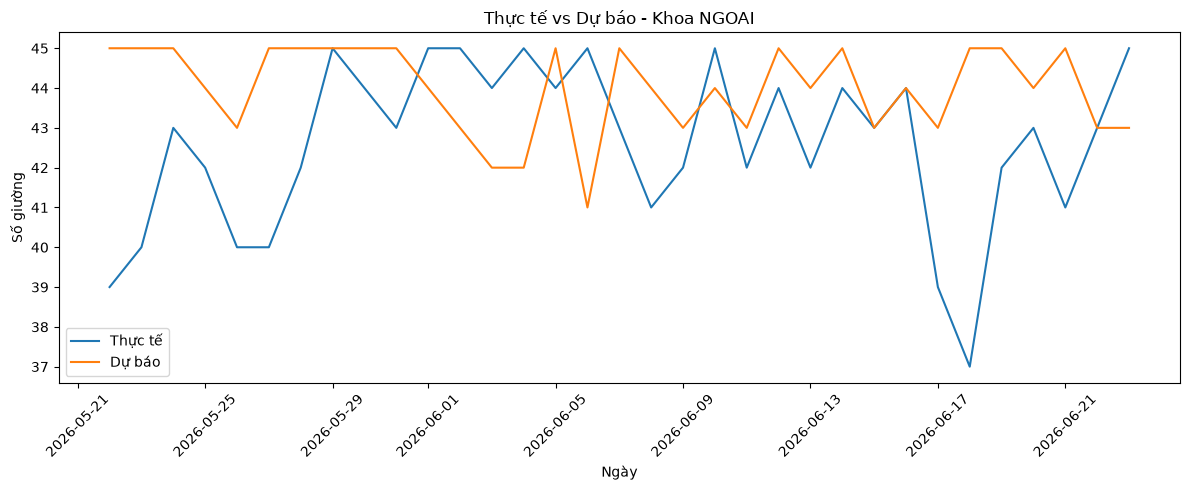

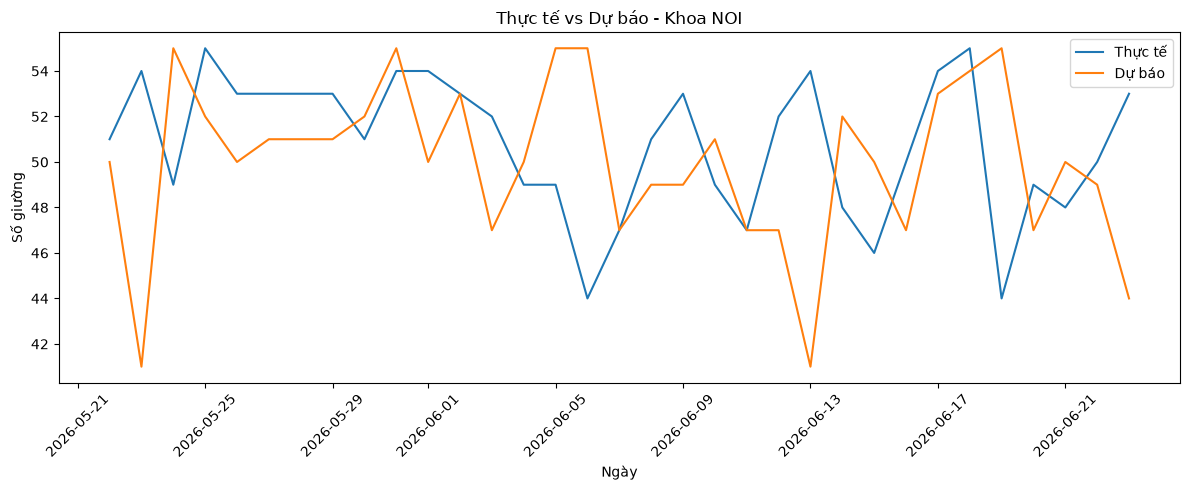

In [ ]:

# ==============================
# 1. THỰC TẾ vs DỰ BÁO
# ==============================

for khoa, df in test_result.groupby("KHOA"):

    df = df.sort_values("NGAY")

    plt.figure(figsize=(12, 5))

    plt.plot(
        df["NGAY"],
        df["THUC_TE"],
        label="Thực tế"
    )

    plt.plot(
        df["NGAY"],
        df["DU_BAO"],
        label="Dự báo"
    )

    plt.title(f"Thực tế vs Dự báo - Khoa {khoa}")
    plt.xlabel("Ngày")
    plt.ylabel("Số giường")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

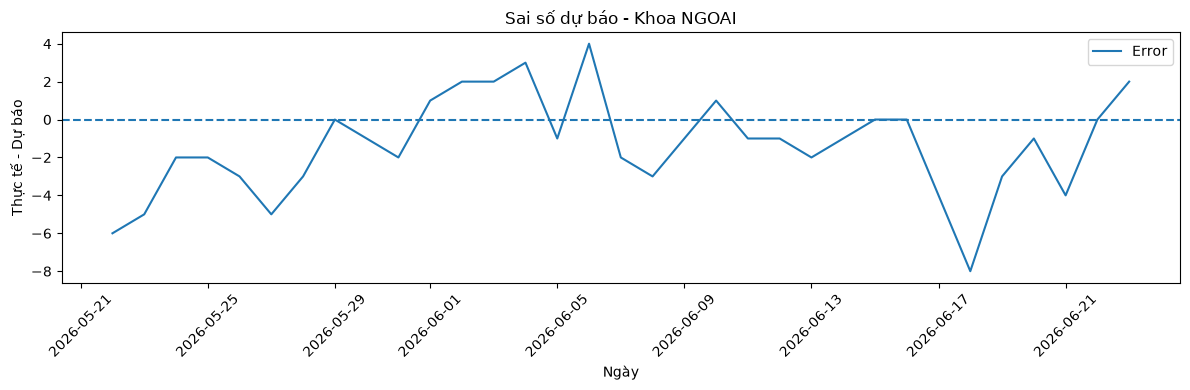

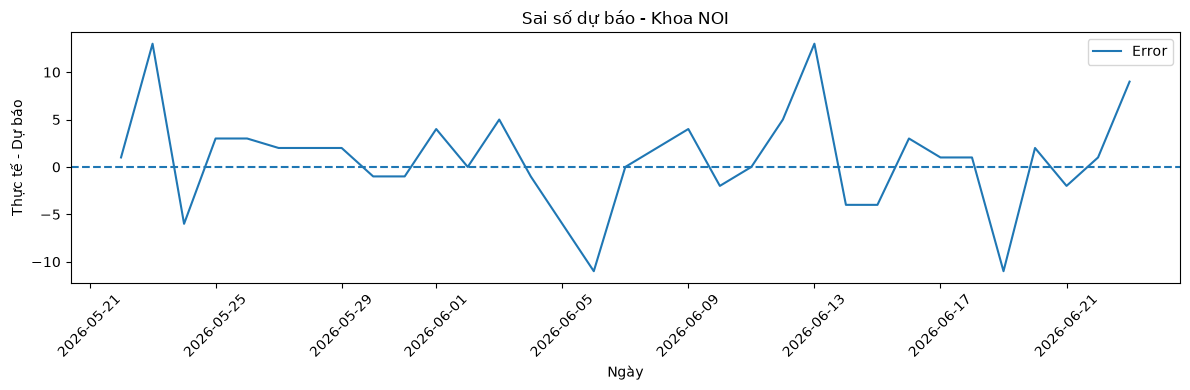

In [ ]:
# ==============================
# 2. SAI SỐ THEO THỜI GIAN
# ==============================

for khoa, df in test_result.groupby("KHOA"):

    df = df.sort_values("NGAY")

    plt.figure(figsize=(12, 4))

    plt.plot(
        df["NGAY"],
        df["ERROR"],
        label="Error"
    )

    # Đường 0 = dự báo hoàn toàn chính xác
    plt.axhline(0, linestyle="--")

    plt.title(f"Sai số dự báo - Khoa {khoa}")
    plt.xlabel("Ngày")
    plt.ylabel("Thực tế - Dự báo")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

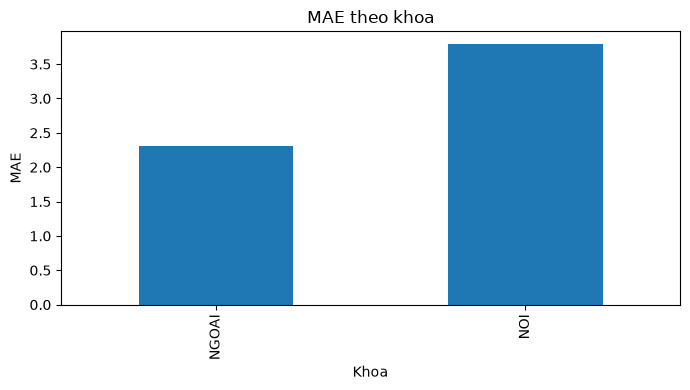

In [ ]:
# ==============================
# 3. MAE THEO KHOA
# ==============================

mae_by_khoa = (
    test_result
    .groupby("KHOA")["ABS_ERROR"]
    .mean()
)

plt.figure(figsize=(7, 4))

mae_by_khoa.plot(
    kind="bar"
)

plt.title("MAE theo khoa")
plt.xlabel("Khoa")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()

In [ ]:
# ==============================
# SO SÁNH VỚI BASELINE
# ==============================

# Dự báo ngày mai = số giường hiện tại
lag1_idx = FEATURE_COLUMNS.index("LAG_1")

baseline_pred = X_test[:, lag1_idx]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

comparison = pd.DataFrame([
    {
        "Model": "Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2,
    },
    {
        "Model": best_model_name,
        "MAE": test_mae,
        "RMSE": test_rmse,
        "R2": test_r2,
    }
])

print(comparison)

      Model       MAE      RMSE        R2
0  Baseline  2.954545  3.863191  0.365143
1       KNN  3.045455  4.251559  0.231082


In [ ]:
# MAE giảm bao nhiêu % so với Baseline
mae_improvement = (
    (baseline_mae - test_mae)
    / baseline_mae
    * 100
)

print(
    f"MAE improvement: {mae_improvement:.2f}%"
)

MAE improvement: -3.08%


In [ ]:
# ==============================
# SO SÁNH FEATURE SET
# ==============================

FEATURE_SETS = {
    "Current": FEATURE_COLUMNS,

    "Lag": [
        "LAG_1",
        "LAG_7",
    ],

    "Lag_Rolling": [
        "LAG_1",
        "LAG_7",
        "ROLL_MEAN_3",
        "ROLL_MEAN_7",
        "ROLL_STD_7",
    ],
}

feature_results = []

for feature_name, feature_cols in FEATURE_SETS.items():

    X_feature = model_data[feature_cols].to_numpy(dtype=float)

    fold_mae = []

    for train_idx, val_idx in folds:

        model = clone(mo_hinh[best_model_name])

        model.fit(
            X_feature[train_idx],
            y[train_idx]
        )

        pred = model.predict(
            X_feature[val_idx]
        )

        fold_mae.append(
            mean_absolute_error(
                y[val_idx],
                pred
            )
        )

    feature_results.append({
        "Feature Set": feature_name,
        "MAE Mean": np.mean(fold_mae),
        "MAE Std": np.std(fold_mae),
    })

feature_results_df = (
    pd.DataFrame(feature_results)
    .sort_values("MAE Mean")
    .reset_index(drop=True)
)

print(feature_results_df)

   Feature Set  MAE Mean   MAE Std
0      Current  2.813636  0.867503
1  Lag_Rolling  2.900000  1.019601
2          Lag  3.195455  0.788816


In [ ]:
# ==============================
# CHỌN FEATURE SET TỐT NHẤT
# ==============================

best_feature_name = (
    feature_results_df
    .sort_values("MAE Mean")
    .iloc[0]["Feature Set"]
)

best_feature_cols = FEATURE_SETS[best_feature_name]

print("Best Feature Set:", best_feature_name)
print("Features:", best_feature_cols)

Best Feature Set: Current
Features: ['SO_GIUONG_KE_HOACH', 'DOW', 'MONTH', 'BN_CUOI_NGAY', 'SO_BN_NHAP_VIEN', 'SO_BN_CHUYEN_DEN', 'SO_BN_RA_VIEN', 'SO_BN_CHUYEN_DI', 'CONG_SUAT_GIUONG', 'NET_FLOW', 'LAG_1', 'LAG_7', 'ROLL_MEAN_3', 'ROLL_MEAN_7', 'ROLL_STD_7', 'KHOA_NOI', 'KHOA_NGOAI']


In [ ]:
# Dùng đúng feature set đã được chọn bằng CV
X_best = model_data[best_feature_cols].to_numpy(dtype=float)
X_best_train = X_best[train_mask]
X_best_test = X_best[test_mask]

y_best_train = y[train_mask]
y_best_test = y[test_mask]

In [ ]:
# ==============================
# BENCHMARK MODEL TRÊN FEATURE SET TỐT NHẤT
# ==============================

final_cv_results = []

for name, model in mo_hinh.items():

    fold_mae = []
    fold_rmse = []
    fold_r2 = []

    for train_idx, val_idx in folds:

        model_fold = clone(model)

        model_fold.fit(
            X_best[train_idx],
            y[train_idx]
        )

        pred = model_fold.predict(
            X_best[val_idx]
        )

        fold_mae.append(
            mean_absolute_error(
                y[val_idx],
                pred
            )
        )

        fold_rmse.append(
            np.sqrt(
                mean_squared_error(
                    y[val_idx],
                    pred
                )
            )
        )

        fold_r2.append(
            r2_score(
                y[val_idx],
                pred
            )
        )

    final_cv_results.append({
        "Model": name,
        "MAE": np.mean(fold_mae),
        "RMSE": np.mean(fold_rmse),
        "R2": np.mean(fold_r2),
    })

final_cv_results_df = (
    pd.DataFrame(final_cv_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print(final_cv_results_df)

/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mr-thai/Projects/active/AI-Number_Beds/.venv/lib/python3.1

                 Model       MAE      RMSE        R2
0                  KNN  2.813636  4.220578  0.157067
1          Naive Bayes  2.877273  3.839849  0.323482
2             AdaBoost  2.918182  4.268791  0.116469
3                  SVM  2.950000  4.017253  0.259526
4    Gradient Boosting  3.068182  4.327426  0.116366
5          Extra Trees  3.113636  4.479196  0.023847
6        Decision Tree  3.318182  4.821008 -0.108974
7        Random Forest  3.531818  4.841302 -0.083327
8  Logistic Regression  3.986364  5.362108 -0.497582


In [ ]:
best_model_name = final_cv_results_df.iloc[0]["Model"]

print("Best Feature Set:", best_feature_name)
print("Best Model:", best_model_name)

Best Feature Set: Current
Best Model: KNN


In [ ]:
# ==============================
# FINAL TEST
# ==============================

final_model = clone(
    mo_hinh[best_model_name]
)

# Train trên toàn bộ TRAIN
final_model.fit(
    X_best_train,
    y_best_train
)

# Chỉ sử dụng FINAL TEST ở đây
final_pred = final_model.predict(
    X_best_test
)

final_mae = mean_absolute_error(
    y_best_test,
    final_pred
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_best_test,
        final_pred
    )
)

final_r2 = r2_score(
    y_best_test,
    final_pred
)

print("\nFINAL RESULT")
print(f"Feature Set : {best_feature_name}")
print(f"Model       : {best_model_name}")
print(f"MAE         : {final_mae:.4f}")
print(f"RMSE        : {final_rmse:.4f}")
print(f"R2          : {final_r2:.4f}")


FINAL RESULT
Feature Set : Current
Model       : KNN
MAE         : 3.0455
RMSE        : 4.2516
R2          : 0.2311


In [ ]:
# ==============================
# DỰ BÁO NGÀY TIẾP THEO
# ==============================

# Lấy ngày cuối cùng trong dữ liệu
last_date = model_data["NGAY"].max()

# Các dòng thuộc ngày cuối cùng
latest_data = model_data[
    model_data["NGAY"] == last_date
].copy()

# Chỉ lấy feature đã được chọn ở GĐ11
X_next = latest_data[
    best_feature_cols
].to_numpy(dtype=float)

# Dự báo số giường ngày tiếp theo
next_pred = final_model.predict(X_next)

# Không thể có số giường âm
next_pred = np.maximum(next_pred, 0)

# Làm tròn về số giường
next_pred = np.rint(next_pred).astype(int)

# Kết quả cuối cùng
forecast = latest_data[["NGAY"]].copy()

# Khôi phục tên khoa từ 2 cột dummy
forecast["KHOA"] = np.where(
    latest_data["KHOA_NOI"] == 1,
    "NOI",
    "NGOAI"
)

forecast["NGAY_DU_BAO"] = (
    last_date + pd.Timedelta(days=1)
)

forecast["SO_GIUONG_DU_BAO"] = next_pred

forecast

,NGAY,KHOA,NGAY_DU_BAO,SO_GIUONG_DU_BAO
332,2026-06-23,NGOAI,2026-06-24,43
333,2026-06-23,NOI,2026-06-24,44


In [ ]:
model_data["NGAY"] = pd.to_datetime(
    model_data["NGAY"]
)

In [ ]:
# ==============================
# KIỂM TRA FEATURE DỰ BÁO
# ==============================

# Kiểm tra feature bị thiếu
missing_features = [
    col for col in best_feature_cols
    if col not in latest_data.columns
]

if missing_features:
    raise ValueError(
        f"Thiếu feature: {missing_features}"
    )

# Kiểm tra giá trị NaN
if latest_data[best_feature_cols].isna().any().any():
    raise ValueError(
        "Feature dùng để dự báo đang chứa NaN."
    )

print("Feature prediction hợp lệ.")

Feature prediction hợp lệ.
